# Classification: Corporate Financial Distress Risk

| Key | Value |
|:---|:---|
| **Course** | Business Intelligence |
| **Lab** | Classification |
| **Dataset** | `corporate_financial_distress.csv` |
| **Target** | `distress_risk_category` (`Healthy` / `Watch` / `Distressed`) |

**Business context**: "Amani Capital Advisory" is a *fictional* credit-research desk that
supports a portfolio manager overseeing a basket of corporate bonds and loans. Before the
portfolio manager decides whether to hold, trim, or exit exposure to a company — and before
the credit team sets a monitoring cadence — they need an evidence-based estimate of how close
that company is to financial distress. Analysts currently review filings by hand once a
quarter, which does not scale as the portfolio grows and is inconsistent across analysts.

The desk classifies every company into one of three tiers:

- **Healthy** – no near-term concern, standard quarterly monitoring
- **Watch** – early warning signs, monitoring cadence increased, may trigger a position review
- **Distressed** – material risk of default, escalated to the credit committee

This is a **decision-support** tool for analysts, not an automatic sell trigger — a human
credit committee still makes the final call on Distressed flags.

As is typical for corporate portfolios, most companies are not in trouble: the classes are
imbalanced, with roughly 70% `Healthy`, 20% `Watch`, and 10% `Distressed`. Correctly
recognising the minority `Distressed` class matters more than overall accuracy, since missing
a distressed company is far costlier to the fund than being extra cautious about a healthy one.

**Learning objectives**: by the end of this notebook you should be able to
- detect and quantify class imbalance,
- correctly sequence a stratified train/test split relative to preprocessing,
- distinguish structural missingness from missingness-at-random and treat each appropriately,
- build and compare several classifiers inside a single pipeline without leaking information,
- read classification-specific diagnostics for an imbalanced multi-class problem,
- tune hyperparameters, and
- explain individual predictions and persist the fitted pipeline correctly.


## Load and Import Required Libraries

We install the libraries required for data handling, visualisation, modelling, resampling,
and explainability, then import them.

In [1]:
import sys
# Installed quietly; only errors are surfaced so the notebook output stays readable
%pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn shap lime joblib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# Fixed seed used everywhere a stochastic step occurs, so the notebook is reproducible
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

import warnings
warnings.filterwarnings("ignore")

print("Environment ready.")

Environment ready.


## Load the Data

The dataset is hosted on GitHub. We download it once and cache it locally, then confirm its
shape and data types before doing anything else — this catches column-count or encoding
problems early, before they surface as confusing errors further down the notebook.

In [3]:
import os
import urllib.request

dataset_path = "./data/corporate_financial_distress.csv"
url = "https://raw.githubusercontent.com/course-files/RegressionAndClassification/main/data/corporate_financial_distress.csv"

if not os.path.exists(dataset_path):
    os.makedirs("./data", exist_ok=True)
    urllib.request.urlretrieve(url, dataset_path)
    print("Dataset downloaded.")
else:
    print("Dataset already exists locally.")

distress_data = pd.read_csv(dataset_path, encoding="utf-8")
print(f"Shape: {distress_data.shape[0]} rows, {distress_data.shape[1]} columns")
distress_data.head()

Dataset already exists locally.
Shape: 1400 rows, 15 columns


,company_id,industry_sector,listing_status,credit_rating_band,audit_going_concern_flag,years_in_operation,num_employees,debt_to_equity_ratio,current_ratio,interest_coverage_ratio,revenue_growth_pct,net_profit_margin_pct,working_capital_to_assets_ratio,macroeconomic_interest_rate_pct,distress_risk_category
0,1,Manufacturing,Private,Investment Grade,NaN,6.1,92,1.05,0.65,12.25,8.19,25.440924,-0.025,14.15,Healthy
1,2,Manufacturing,Private,High Risk,NaN,8.9,158,0.24,1.74,7.46,4.55,3.558157,0.139,10.17,Healthy
2,3,Manufacturing,Private,Investment Grade,NaN,39.1,587,2.53,1.32,-0.15,4.15,NaN,0.082,14.42,Healthy
3,4,Energy,Private,Investment Grade,NaN,16.3,49,0.44,2.36,9.51,8.56,-8.063747,0.242,13.41,Healthy
4,5,Manufacturing,Public,Investment Grade,No,9.2,157,1.92,1.56,4.20,2.57,-4.546986,0.039,14.76,Healthy


In [4]:
distress_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 15 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   company_id                       1400 non-null   int64  
 1   industry_sector                  1400 non-null   str    
 2   listing_status                   1400 non-null   str    
 3   credit_rating_band               1400 non-null   str    
 4   audit_going_concern_flag         398 non-null    str    
 5   years_in_operation               1400 non-null   float64
 6   num_employees                    1400 non-null   int64  
 7   debt_to_equity_ratio             1400 non-null   float64
 8   current_ratio                    1400 non-null   float64
 9   interest_coverage_ratio          1400 non-null   float64
 10  revenue_growth_pct               1400 non-null   float64
 11  net_profit_margin_pct            1322 non-null   float64
 12  working_capital_to_assets_ratio

`company_id` is a unique identifier and carries no predictive signal, so it is dropped
before modelling but kept out of the feature list rather than out of the dataframe, in case we
need it later to trace a prediction back to a specific company.

In [5]:
ID_COLUMN = "company_id"
TARGET = "distress_risk_category"
distress_data[TARGET].value_counts()

distress_risk_category
Healthy       980
Watch         280
Distressed    140
Name: count, dtype: int64

## Initial Exploratory Data Analysis

### Measures of Frequency

The class counts above already hint at imbalance; we express it as percentages to make the
70/20/10 split explicit, and look at the frequency of the categorical predictors too.

In [6]:
print("Target distribution (%):")
print((distress_data[TARGET].value_counts(normalize=True) * 100).round(1))

categorical_cols = ["industry_sector", "listing_status", "credit_rating_band", "audit_going_concern_flag"]
for col in categorical_cols:
    print(f"\n{col}:")
    print(distress_data[col].value_counts(dropna=False))

Target distribution (%):
distress_risk_category
Healthy       70.0
Watch         20.0
Distressed    10.0
Name: proportion, dtype: float64

industry_sector:
industry_sector
Manufacturing    358
Construction     276
Retail           276
Technology       270
Energy           220
Name: count, dtype: int64

listing_status:
listing_status
Private    1002
Public      398
Name: count, dtype: int64

credit_rating_band:
credit_rating_band
Investment Grade    626
Speculative         509
High Risk           265
Name: count, dtype: int64

audit_going_concern_flag:
audit_going_concern_flag
NaN    1002
No      345
Yes      53
Name: count, dtype: int64


### Measures of Central Tendency and Dispersion

`describe()` gives mean, spread, and quartiles for every numeric column in one call, which is
enough to spot columns that might need transformation before modelling (e.g. heavily
right-skewed ratios).

In [7]:
numeric_cols = distress_data.select_dtypes(include=[np.number]).columns.drop(ID_COLUMN)
distress_data[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
years_in_operation,1400.0,12.199571,8.413296,0.500000,6.075000,10.450000,16.400000,69.400000
num_employees,1400.0,301.251429,221.363333,5.000000,143.000000,247.000000,405.250000,1736.000000
debt_to_equity_ratio,1400.0,1.392471,1.002373,0.050000,0.660000,1.095000,1.930000,7.410000
current_ratio,1400.0,1.623271,0.709583,0.100000,1.120000,1.650000,2.140000,3.870000
interest_coverage_ratio,1400.0,4.488479,5.307081,-11.520000,0.732500,4.580000,8.065000,24.290000
revenue_growth_pct,1400.0,4.149429,8.833111,-23.450000,-1.775000,3.965000,9.865000,29.420000
net_profit_margin_pct,1322.0,5.800128,8.708269,-22.509476,-0.181029,5.638433,11.686121,37.515585
working_capital_to_assets_ratio,1400.0,0.111557,0.139118,-0.262000,0.017000,0.098000,0.197000,0.600000
macroeconomic_interest_rate_pct,1400.0,13.514464,1.981165,6.810000,12.247500,13.520000,14.870000,20.740000


### Measures of Distribution

Skewness and kurtosis flag numeric columns that depart strongly from a symmetric,
normal-like shape — useful context for later deciding whether scaling alone is enough or a
power transform would help a distance- or gradient-based model.

In [8]:
shape_summary = pd.DataFrame({
    "skewness": distress_data[numeric_cols].apply(lambda s: stats.skew(s.dropna())),
    "kurtosis": distress_data[numeric_cols].apply(lambda s: stats.kurtosis(s.dropna())),
}).round(2)
shape_summary

,skewness,kurtosis
years_in_operation,1.49,3.54
num_employees,1.55,3.61
debt_to_equity_ratio,1.38,2.60
current_ratio,-0.01,-0.38
interest_coverage_ratio,0.10,0.03
revenue_growth_pct,-0.01,-0.06
net_profit_margin_pct,0.11,0.06
working_capital_to_assets_ratio,0.38,0.30
macroeconomic_interest_rate_pct,-0.11,0.28


### Measures of Relationship

For numeric predictors we use a one-way ANOVA F-test against the target: a large F (and small
p-value) means the predictor's mean differs meaningfully across the three risk tiers. For
categorical predictors we use Cramer's V, which measures association strength between two
categorical variables independent of sample size. Both are exploratory only — the same tests
are re-run properly on the training fold alone during feature selection, to avoid leaking
test-set information into that decision.

In [9]:
from scipy.stats import f_oneway

def anova_f_for_target(df, num_col, target_col):
    groups = [df.loc[df[target_col] == cat, num_col].dropna() for cat in df[target_col].unique()]
    f_stat, p_val = f_oneway(*groups)
    return f_stat, p_val

anova_results = []
for col in numeric_cols:
    f_stat, p_val = anova_f_for_target(distress_data, col, TARGET)
    anova_results.append({"feature": col, "F_statistic": f_stat, "p_value": p_val})

anova_df = pd.DataFrame(anova_results).sort_values("F_statistic", ascending=False)
anova_df

,feature,F_statistic,p_value
2,debt_to_equity_ratio,47.398161,1.212221e-20
4,interest_coverage_ratio,44.202109,2.433323e-19
6,net_profit_margin_pct,39.077061,3.256987e-17
3,current_ratio,31.108899,6.050443e-14
7,working_capital_to_assets_ratio,27.801875,1.445099e-12
5,revenue_growth_pct,25.622202,1.179372e-11
8,macroeconomic_interest_rate_pct,0.322126,7.246607e-01
0,years_in_operation,0.225617,7.980530e-01
1,num_employees,0.061872,9.400054e-01


In [10]:
def cramers_v(x, y):
    confusion = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion)[0]
    n = confusion.sum().sum()
    r, k = confusion.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1))

cramers_results = []
for col in categorical_cols:
    valid = distress_data[[col, TARGET]].dropna()
    v = cramers_v(valid[col], valid[TARGET])
    cramers_results.append({"feature": col, "cramers_v": v})

pd.DataFrame(cramers_results).sort_values("cramers_v", ascending=False)

,feature,cramers_v
2,credit_rating_band,0.113714
3,audit_going_concern_flag,0.085151
0,industry_sector,0.077373
1,listing_status,0.041259


`years_in_operation`, `num_employees`, and `macroeconomic_interest_rate_pct` show weak
association with risk tier (low F-statistics), while the leverage and profitability ratios
show much stronger association — consistent with credit-risk intuition that a firm's own
financial health, not the macro backdrop it happens to sit in, is what drives its distress
tier here.

### Basic Visualisation

A boxplot of the strongest numeric signal (`interest_coverage_ratio`) across risk tiers, and a
bar chart of the target distribution, give a quick visual check on the patterns found above.

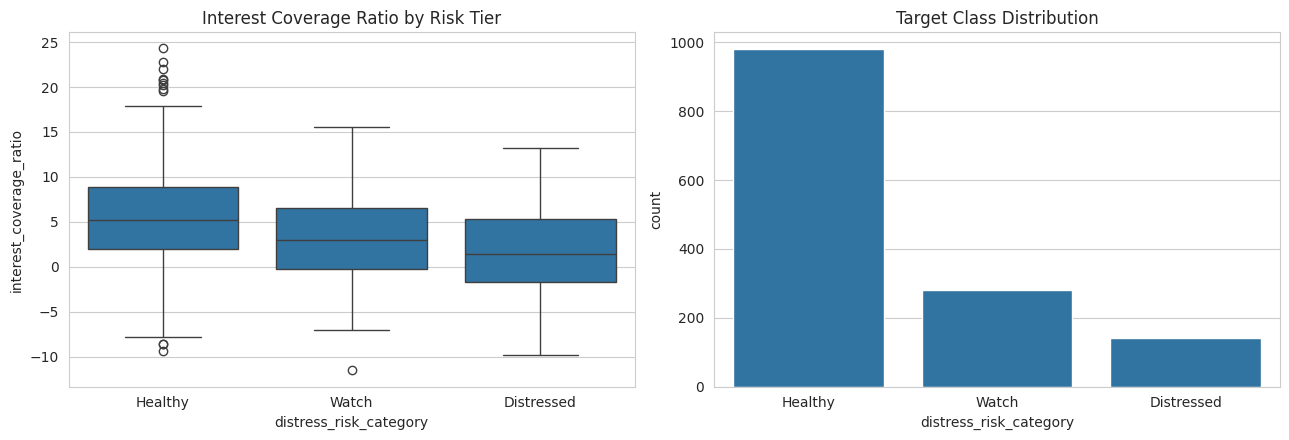

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = ["Healthy", "Watch", "Distressed"]
sns.boxplot(data=distress_data, x=TARGET, y="interest_coverage_ratio", order=order, ax=axes[0])
axes[0].set_title("Interest Coverage Ratio by Risk Tier")

sns.countplot(data=distress_data, x=TARGET, order=order, ax=axes[1])
axes[1].set_title("Target Class Distribution")

plt.tight_layout()
plt.show()

## Train/Test Split

The split happens **before** any preprocessing, feature selection, or resampling. Fitting an
imputer, scaler, or feature selector on the full dataset would let information about the test
set leak into the training process, giving an overly optimistic performance estimate. The
split is stratified on the target so that the 70/20/10 class proportions are preserved in both
the training and test folds.

In [12]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in distress_data.columns if c not in (ID_COLUMN, TARGET)]
X = distress_data[feature_cols].copy()
y = distress_data[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("\nTrain class balance (%):")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("\nTest class balance (%):")
print((y_test.value_counts(normalize=True) * 100).round(1))

Train: 1120 rows | Test: 280 rows

Train class balance (%):
distress_risk_category
Healthy       70.0
Watch         20.0
Distressed    10.0
Name: proportion, dtype: float64

Test class balance (%):
distress_risk_category
Healthy       70.0
Watch         20.0
Distressed    10.0
Name: proportion, dtype: float64


## Feature Selection *(performed on training data only)*

We re-run the same association tests from the EDA, but strictly on `X_train`/`y_train`, to
decide which predictors are worth keeping. This mirrors the earlier exploratory results and
confirms that `years_in_operation`, `num_employees`, and `macroeconomic_interest_rate_pct`
carry little independent signal for this target.

### ANOVA F-test (numeric predictors)

In [13]:
from sklearn.feature_selection import f_classif, mutual_info_classif

numeric_features = list(X_train[feature_cols].select_dtypes(include=[np.number]).columns)
categorical_features = [c for c in feature_cols if c not in numeric_features]

# ANOVA F-test needs complete cases; net_profit_margin_pct has a few missing values
numeric_train_complete = X_train[numeric_features].fillna(X_train[numeric_features].median())

f_scores, f_pvalues = f_classif(numeric_train_complete, y_train)
mi_scores = mutual_info_classif(numeric_train_complete, y_train, random_state=RANDOM_STATE)

numeric_selection = pd.DataFrame({
    "feature": numeric_features,
    "anova_F": f_scores,
    "anova_p": f_pvalues,
    "mutual_info": mi_scores,
}).sort_values("anova_F", ascending=False)
numeric_selection

,feature,anova_F,anova_p,mutual_info
2,debt_to_equity_ratio,43.331252,7.512849e-19,0.041681
4,interest_coverage_ratio,38.675449,5.747889e-17,0.039535
6,net_profit_margin_pct,34.442373,3.054715e-15,0.047386
3,current_ratio,29.604470,2.965631e-13,0.030879
7,working_capital_to_assets_ratio,24.814872,2.854904e-11,0.026110
5,revenue_growth_pct,19.462105,4.916429e-09,0.038013
0,years_in_operation,0.528996,5.893435e-01,0.004690
1,num_employees,0.285873,7.514127e-01,0.018701
8,macroeconomic_interest_rate_pct,0.004540,9.954702e-01,0.000000


### Chi-square test (categorical predictors)

`audit_going_concern_flag` is structurally missing for private companies (see the next
section), so it is excluded from this particular test — its relationship with the target is
assessed later, after that missingness has been made explicit as its own signal.

In [14]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import OrdinalEncoder

chi2_features = [c for c in categorical_features if c != "audit_going_concern_flag"]
encoder_for_chi2 = OrdinalEncoder()
categorical_encoded = encoder_for_chi2.fit_transform(X_train[chi2_features])

chi2_scores, chi2_pvalues = chi2(categorical_encoded, y_train)
pd.DataFrame({"feature": chi2_features, "chi2": chi2_scores, "p_value": chi2_pvalues}).sort_values("chi2", ascending=False)

,feature,chi2,p_value
0,industry_sector,4.861745,0.087960
2,credit_rating_band,3.710890,0.156383
1,listing_status,0.840970,0.656728


Based on both tests, `debt_to_equity_ratio`, `interest_coverage_ratio`,
`net_profit_margin_pct`, `revenue_growth_pct`, `current_ratio`, and `working_capital_to_assets_ratio`
are the strongest numeric predictors, and `credit_rating_band` is the strongest categorical
one. `years_in_operation`, `num_employees`, and `macroeconomic_interest_rate_pct` are weak but
are kept in — a Random Forest / boosted model can down-weight a weak feature on its own, and
dropping them risks discarding a small amount of genuine signal for little benefit.

## Data Preprocessing and Transformation *(fit on training data only)*

### Handling Missing Data

Two columns have missing values, and they are missing for different reasons — treating them
the same way would be a modelling error:

- **`audit_going_concern_flag`** is missing for every `Private` company (structural
  missingness): a formal going-concern opinion is a feature of statutory audits, which private
  firms in this dataset are not required to obtain. There is no value to impute here — the
  absence itself is informative, so it is encoded as its own category (`"Not Applicable"`)
  rather than guessed at.
- **`net_profit_margin_pct`** is missing for ~5.5% of companies, roughly evenly across risk
  tiers (missing at random). Here a median imputation is appropriate, paired with a missing-
  indicator flag so the model can still learn from *whether* a value was missing.

Both are implemented as pipeline steps below (not applied to the full dataframe directly) so
that all statistics used for imputation are learned from the training fold only.

In [15]:
print("audit_going_concern_flag missing, by listing_status:")
print(pd.crosstab(X_train["listing_status"], X_train["audit_going_concern_flag"].isna()))

print("\nnet_profit_margin_pct missing, by risk tier:")
print(pd.crosstab(y_train, X_train["net_profit_margin_pct"].isna()))

audit_going_concern_flag missing, by listing_status:
audit_going_concern_flag  False  True 
listing_status                        
Private                       0    802
Public                      318      0

net_profit_margin_pct missing, by risk tier:
net_profit_margin_pct   False  True 
distress_risk_category              
Distressed                102     10
Healthy                   737     47
Watch                     214     10


### Encoding, Scaling, and Class Imbalance

- **`credit_rating_band`** has a natural order (`High Risk` < `Speculative` < `Investment Grade`)
  and is ordinal-encoded to preserve it; the other categorical columns are nominal and are
  one-hot encoded.
- Numeric predictors are median-imputed (for `net_profit_margin_pct`) and standardised, since
  several downstream models (logistic regression, distance- and gradient-based methods) are
  sensitive to feature scale.
- **Class imbalance** (70/20/10) is handled with SMOTE inside the pipeline, applied only to the
  training folds during cross-validation and never to the test set — otherwise synthetic
  points derived from test-set neighbours would leak test information into training.

All of this is assembled into a single `ColumnTransformer` + `imblearn` `Pipeline`, so the
exact same fitted transformations are applied consistently to train, validation, and test
data, and a single object can later be persisted.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RATING_ORDER = [["High Risk", "Speculative", "Investment Grade"]]

nominal_features = ["industry_sector", "listing_status", "audit_going_concern_flag"]
ordinal_features = ["credit_rating_band"]

# audit_going_concern_flag's missingness is structural, so it is filled with an explicit
# category rather than imputed statistically
nominal_transformer = Pipeline(steps=[
    ("impute_not_applicable", SimpleImputer(strategy="constant", fill_value="Not Applicable")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

ordinal_transformer = Pipeline(steps=[
    ("ordinal", OrdinalEncoder(categories=RATING_ORDER)),
])

# net_profit_margin_pct's missingness is at random, so a median fill plus an indicator flag
# lets the model use both the value and the fact that it was missing
numeric_transformer = Pipeline(steps=[
    ("impute_median", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("nom", nominal_transformer, nominal_features),
    ("ord", ordinal_transformer, ordinal_features),
])

print("Preprocessor assembled.")

Preprocessor assembled.


## Machine Learning Pipeline and Cross-Validation

We compare three classifiers that are commonly contrasted in credit-risk work: a linear
baseline (Logistic Regression), and two tree ensembles (Random Forest, Gradient Boosting).
Each is wrapped in the same preprocessing + SMOTE pipeline, so the comparison isolates the
effect of the model itself. `StratifiedKFold` keeps the 70/20/10 class ratio in every fold.

Macro-averaged F1 is used as the primary metric (it weights all three classes equally,
so the majority `Healthy` class cannot mask poor performance on `Distressed`), alongside
balanced accuracy as a second check.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["f1_macro", "balanced_accuracy"]

candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

comparison_rows = []
for name, model in candidate_models.items():
    pipeline = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("resample", SMOTE(random_state=RANDOM_STATE)),
        ("classify", model),
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    comparison_rows.append({
        "model": name,
        "f1_macro_mean": scores["test_f1_macro"].mean(),
        "f1_macro_std": scores["test_f1_macro"].std(),
        "balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values("f1_macro_mean", ascending=False)
model_comparison

,model,f1_macro_mean,f1_macro_std,balanced_accuracy_mean
0,Logistic Regression,0.501091,0.023784,0.555821
1,Random Forest,0.455161,0.035619,0.447190
2,Gradient Boosting,0.450945,0.018958,0.452791


Whether a linear model or a tree ensemble wins is an empirical question here: the tree
ensembles can capture interactions between ratios (e.g. a high debt-to-equity ratio being far
more concerning when interest coverage is also low), but with a modest training set and only a
handful of strong predictors, a regularised linear model can still match or beat them. The
best-performing model by `f1_macro_mean` above is carried forward.

In [18]:
best_model_name = model_comparison.iloc[0]["model"]
best_model = candidate_models[best_model_name]
print(f"Selected model: {best_model_name}")

best_pipeline = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("resample", SMOTE(random_state=RANDOM_STATE)),
    ("classify", best_model),
])
best_pipeline.fit(X_train, y_train)
print("Pipeline fitted on the training set.")

Selected model: Logistic Regression
Pipeline fitted on the training set.


## Diagnostic Exploratory Data Analysis (Model Diagnostics)

### Confusion Matrix and Classification Report

The confusion matrix shows where the model's mistakes land — for a credit desk, confusing
`Watch` and `Distressed` is far less costly than mislabelling a `Distressed` company as
`Healthy`, so the pattern of errors matters as much as the count.

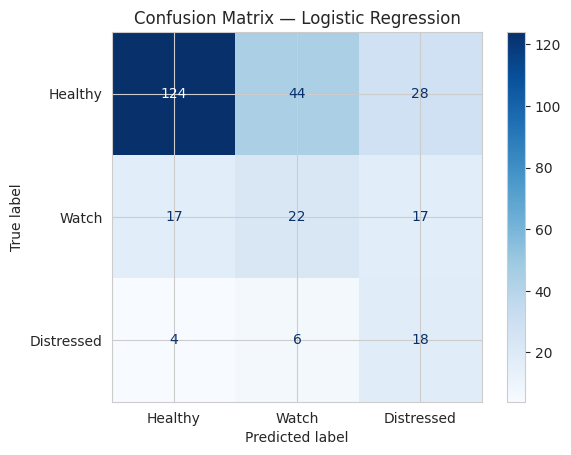

              precision    recall  f1-score   support

     Healthy       0.86      0.63      0.73       196
       Watch       0.31      0.39      0.34        56
  Distressed       0.29      0.64      0.40        28

    accuracy                           0.59       280
   macro avg       0.48      0.56      0.49       280
weighted avg       0.69      0.59      0.62       280



In [19]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = best_pipeline.predict(X_test)
order = ["Healthy", "Watch", "Distressed"]

cm = confusion_matrix(y_test, y_pred, labels=order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=order)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

print(classification_report(y_test, y_pred, labels=order))

### Precision-Recall Curve (per class)

With a 70/20/10 imbalance, ROC curves can look deceptively good even for a weak model on the
minority class, because the large number of true negatives dominates the false-positive rate.
Precision-recall curves are a more honest diagnostic here, particularly for `Distressed`.

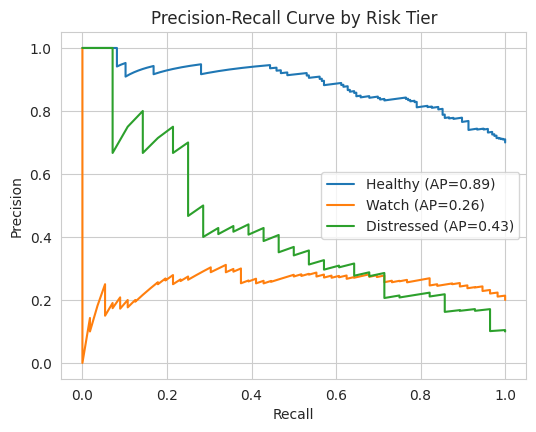

In [20]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

y_test_bin = label_binarize(y_test, classes=order)
y_proba = best_pipeline.predict_proba(X_test)
# Align predict_proba's column order with `order`
proba_order = [list(best_pipeline.classes_).index(cls) for cls in order]
y_proba = y_proba[:, proba_order]

plt.figure(figsize=(6, 4.5))
for i, cls in enumerate(order):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_proba[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_proba[:, i])
    plt.plot(recall, precision, label=f"{cls} (AP={ap:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve by Risk Tier")
plt.legend()
plt.show()

## Hyperparameter Tuning

`RandomizedSearchCV` is used rather than an exhaustive grid search because the number of
parameter combinations across the tree ensemble and the SMOTE step grows quickly, and a
random search covers that space efficiently. Scoring is again `f1_macro`, kept consistent with
the earlier model comparison so results are comparable.

In [21]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "classify__n_estimators": [200, 300, 400, 500],
    "classify__max_depth": [3, 4, 5, 6, None],
    "classify__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "resample__k_neighbors": [3, 5, 7],
} if best_model_name == "Gradient Boosting" else {
    "classify__n_estimators": [200, 300, 400, 500],
    "classify__max_depth": [None, 5, 10, 20],
    "classify__min_samples_leaf": [1, 2, 4],
    "resample__k_neighbors": [3, 5, 7],
} if best_model_name == "Random Forest" else {
    "classify__C": [0.01, 0.1, 1, 10, 100],
    "classify__penalty": ["l2"],
    "resample__k_neighbors": [3, 5, 7],
}

search = RandomizedSearchCV(
    best_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print(f"Best CV f1_macro: {search.best_score_:.3f}")
print("Best parameters:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

tuned_pipeline = search.best_estimator_

Best CV f1_macro: 0.505
Best parameters:
  resample__k_neighbors: 7
  classify__penalty: l2
  classify__C: 1


In [22]:
y_pred_tuned = tuned_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_tuned, labels=order))

              precision    recall  f1-score   support

     Healthy       0.86      0.65      0.74       196
       Watch       0.30      0.39      0.34        56
  Distressed       0.28      0.61      0.39        28

    accuracy                           0.59       280
   macro avg       0.48      0.55      0.49       280
weighted avg       0.69      0.59      0.63       280



## Explainability

A credit committee will not act on a "black box" flag — they need to know *why* a company was
placed in a given tier. Two complementary views are provided: global feature importance
(which features matter most overall) and a local SHAP explanation (why one specific company
was flagged).

### Global Feature Importance

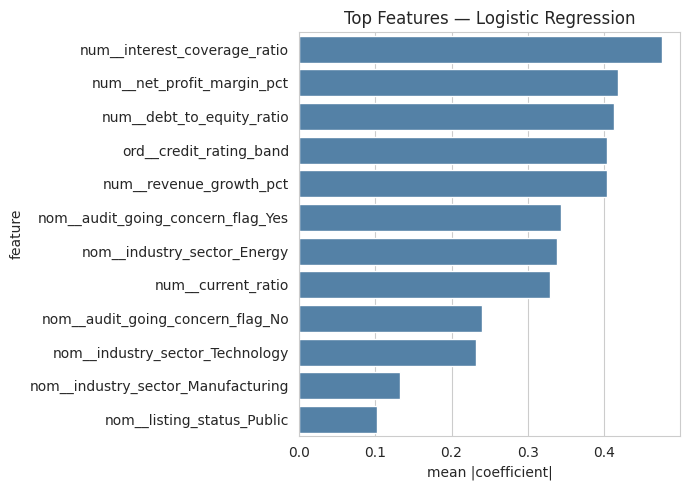

In [23]:
feature_names = tuned_pipeline.named_steps["preprocess"].get_feature_names_out()
classifier = tuned_pipeline.named_steps["classify"]

if hasattr(classifier, "feature_importances_"):
    importances = classifier.feature_importances_
    importance_label = "importance"
else:
    # Logistic regression: use the mean absolute coefficient across the one-vs-rest classes
    importances = np.abs(classifier.coef_).mean(axis=0)
    importance_label = "mean |coefficient|"

importance_df = pd.DataFrame({"feature": feature_names, importance_label: importances})
importance_df = importance_df.sort_values(importance_label, ascending=False).head(12)

plt.figure(figsize=(7, 5))
sns.barplot(data=importance_df, x=importance_label, y="feature", color="steelblue")
plt.title(f"Top Features — {best_model_name}")
plt.tight_layout()
plt.show()

### Local Explanation (SHAP) for a Single Company

We pick one company the model flagged as `Distressed` in the test set and show which features
pushed that specific prediction — this is the level of detail an analyst needs to justify an
escalation to the credit committee.

In [24]:
import shap

distressed_mask = y_pred_tuned == "Distressed"
if distressed_mask.sum() > 0:
    sample_idx = X_test[distressed_mask].index[0]
    X_test_transformed = tuned_pipeline.named_steps["preprocess"].transform(X_test)
    X_test_transformed = pd.DataFrame(X_test_transformed, columns=feature_names, index=X_test.index)

    # TreeExplainer works directly for tree-based models; for logistic regression fall back
    # to a linear explainer on the transformed features
    if hasattr(classifier, "feature_importances_"):
        explainer = shap.TreeExplainer(classifier)
    else:
        explainer = shap.LinearExplainer(classifier, X_test_transformed)

    shap_values = explainer.shap_values(X_test_transformed.loc[[sample_idx]])
    class_index = list(tuned_pipeline.classes_).index("Distressed")
    sv = shap_values[class_index][0] if isinstance(shap_values, list) else shap_values[0, :, class_index]

    shap_summary = pd.DataFrame({
        "feature": feature_names,
        "shap_value": sv,
    }).sort_values("shap_value", key=abs, ascending=False).head(8)
    print(f"Company (row index {sample_idx}) flagged as Distressed — top contributing features:")
    display(shap_summary)
else:
    print("No test-set company was predicted Distressed — skipping the local explanation.")

Background dataset has 280 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=280 when initializing the masker.


Company (row index 1057) flagged as Distressed — top contributing features:


,feature,shap_value
6,num__net_profit_margin_pct,0.758669
20,ord__credit_rating_band,0.726867
2,num__debt_to_equity_ratio,-0.456591
4,num__interest_coverage_ratio,-0.429730
11,nom__industry_sector_Energy,0.401175
3,num__current_ratio,-0.301445
5,num__revenue_growth_pct,0.283177
17,nom__audit_going_concern_flag_No,-0.256461


## Model Persistence

The **entire fitted pipeline** is saved — preprocessing, SMOTE, and the classifier together —
not just the classifier. SMOTE only runs during training (imblearn pipelines automatically
skip it at inference time), so saving the whole object guarantees that any new company scored
later goes through exactly the same encoding, imputation, and scaling used here, with no risk
of applying resampling to live data by mistake.

In [25]:
import joblib

os_makedirs_target = "./models"
import os
os.makedirs(os_makedirs_target, exist_ok=True)

model_path = os.path.join(os_makedirs_target, "distress_risk_pipeline.joblib")
joblib.dump(tuned_pipeline, model_path)
print(f"Pipeline saved to {model_path}")

# Round-trip check: reload and confirm predictions match
reloaded_pipeline = joblib.load(model_path)
assert (reloaded_pipeline.predict(X_test) == tuned_pipeline.predict(X_test)).all()
print("Reload check passed — predictions match.")

Pipeline saved to ./models/distress_risk_pipeline.joblib
Reload check passed — predictions match.


## Summary

- The target (`distress_risk_category`) is imbalanced (~70/20/10), so the split was stratified
  and macro-averaged metrics were used throughout instead of plain accuracy.
- `audit_going_concern_flag` is missing for a structural reason (private companies are not
  required to obtain a going-concern audit opinion) and was encoded as its own category;
  `net_profit_margin_pct` is missing at random and was median-imputed with a missing-indicator
  flag. Applying one rule to both would have discarded a genuine signal in the first column.
- Feature selection and all preprocessing were fitted on the training fold only, and SMOTE was
  applied inside the pipeline so it only ever touches training folds during cross-validation.
- The tuned pipeline's held-out performance and top drivers of `Distressed` classifications are reported above; the credit desk can use the feature-importance and SHAP views to justify escalations to the credit committee rather than treating the flag as a black box.